# Graph 9: Feature importance (permutation importance on the test set)
Run `01_data_processing.ipynb` and `08_modelling.ipynb` first.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
saved = joblib.load("processed/model_results.joblib")
best_name, best_model = saved["best_name"], saved["best_model"]
X_test, y_test, feature_cols = saved["X_test"], saved["y_test"], saved["feature_cols"]

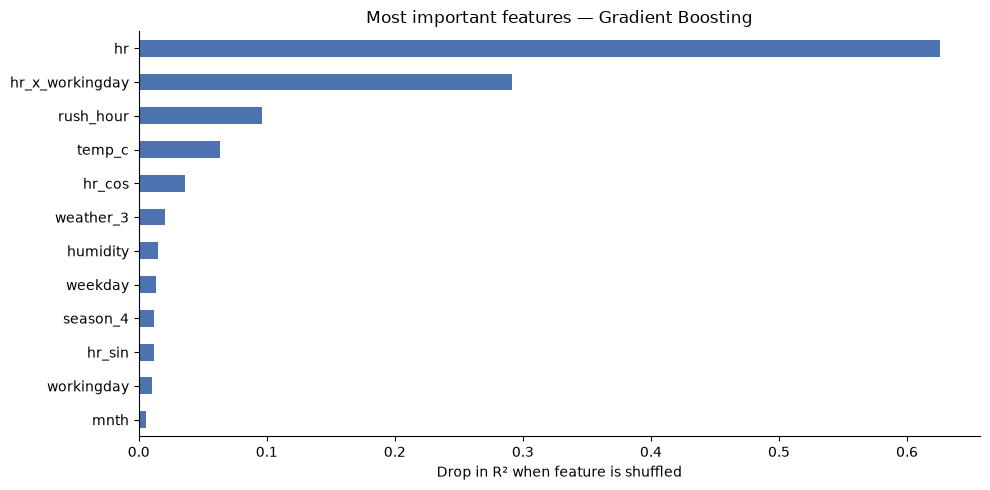

In [3]:
perm = permutation_importance(best_model, X_test, np.log1p(y_test), n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=feature_cols).sort_values()
imp.tail(12).plot(kind="barh", color="#4C72B0")
plt.title(f"Most important features — {best_name}"); plt.xlabel("Drop in R² when feature is shuffled")
plt.tight_layout(); plt.savefig("figures/09_feature_importance.png", dpi=150); plt.show()

## 7. Notes for the Discussion section
Points to check against your own results:
- How much better is the best model than the hourly-average baseline? (That gap is what the ML actually adds.)
- Linear vs tree models: does the gap confirm the non-linear patterns seen in EDA (temperature curve, two peaks)?
- Which hours have the largest errors — the peaks? Why might that be?
- Limitations: recorded rentals ≠ true demand (empty stations), one city, two years, scheme growth (`yr`), very few heavy-rain hours.
- Future work: separate models for casual vs registered riders, events/holiday data, test on another city's data (e.g. London Santander Cycles via TfL open data).